In [1]:
import numpy as np
from qiskit import QuantumCircuit

def qft(circuito, qubits):
    n = len(qubits)

    for s in range(n - 1, -1, -1):
        circuito.h(qubits[s])

        for p in range(s - 1, -1, -1):
            angulo = np.pi / (2 ** (s - p))
            circuito.cp(
                angulo,
                qubits[s],
                qubits[p]
            )
        circuito.barrier()
        
    for s in range(n // 2):
        circuito.swap(qubits[s], qubits[n - 1 - s])

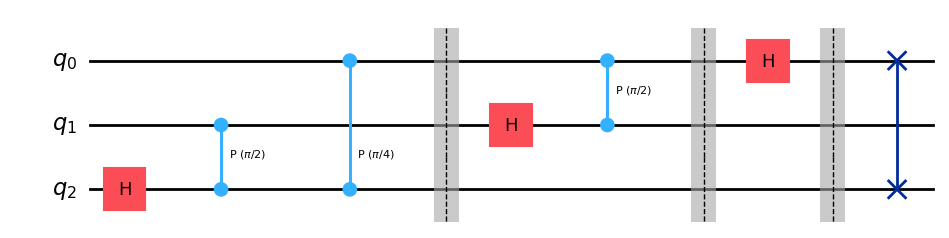

In [2]:
n = 3

circuito = QuantumCircuit(n)
qft(circuito, list(range(n)))

circuito.draw("mpl")

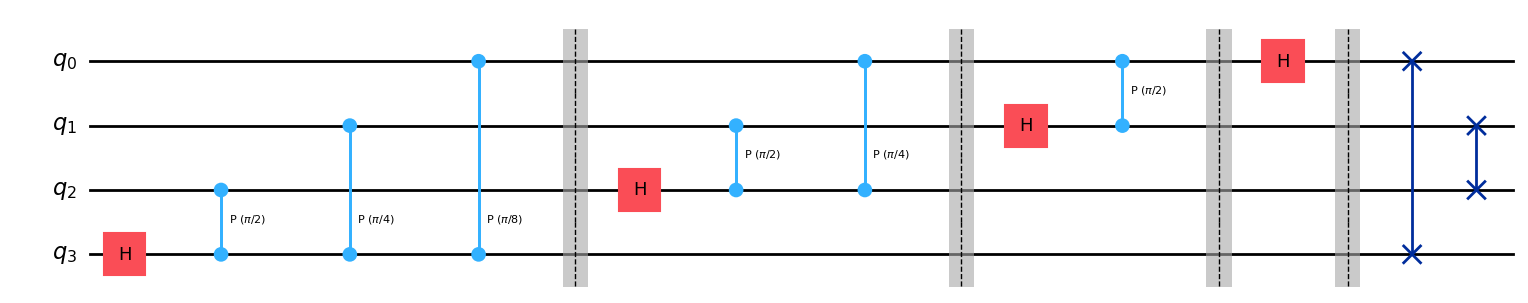

In [3]:
n = 4

circuito = QuantumCircuit(n)
qft(circuito, list(range(n)))

circuito.draw("mpl")

In [4]:
from qiskit.quantum_info import Operator

N = 2 ** n

omega_N = np.exp(2j * np.pi / N)

F = np.array([
    [omega_N ** (k * j) for j in range(N)]
    for k in range(N)
]) / np.sqrt(N)

print(np.allclose(Operator(circuito).data, F))

True
